# Predição de risco de alagamento no Recife — notebook de modelagem

**Objetivo:** treinar e avaliar modelos que estimam a probabilidade de alagamento em um bairro em um dia, a partir de chuva, maré, histórico e características do local. Este notebook cobre os itens 03 a 05 do backlog do projeto (variáveis, modelo e classificação de risco).

**Dados:** `dataset_ml_bairro_dia_completo.csv` — uma linha por *bairro × dia*, 2014–2021 (45 colunas). Dicionário em `dicionario_variaveis.csv`.

## Estratégia (e por que)
Os dados têm três características que ditam todas as escolhas abaixo:

1. **Eventos raros:** ~0,14% das linhas são positivas (314 no rótulo amplo, **162 no estrito**). Por isso usamos **PR-AUC e recall no topo do ranking**, não acurácia (um modelo que diz "nunca alaga" acertaria 99,86%).
2. **Poucos anos e poucos eventos por ano:** uma divisão única treino/teste deixaria o teste com ~24 positivos estritos. Em vez disso usamos **validação "deixa um ano de fora"** (*leave-one-year-out*): treina em 7 anos e testa no 8º, repetindo para todos. As previsões de teste dos 8 anos são juntadas, de modo que **todos os 162 positivos são avaliados** sem nunca terem sido vistos no treino.
3. **Rótulo imperfeito:** o alvo vem de registros da Defesa Civil. Comparamos o rótulo **estrito** (`alagou_estrito`, principal) com o **amplo** (`alagou`).

Também comparamos dois **cenários**:
- **A — "previsão de chuva perfeita":** usa a chuva do próprio dia. Em produção isso exigiria uma *previsão* de chuva, que o projeto ainda não tem. Mostra o **teto** de desempenho.
- **B — "sem previsão":** só usa chuva dos dias *anteriores*, histórico, maré do dia e local. É o que seria possível sem previsão de chuva.

**Como rodar:** `pip3 install pandas scikit-learn matplotlib jupyter` e abra com `jupyter notebook`. Nenhum outro pacote é necessário.

## 1. Configuração e carga dos dados
Importamos as bibliotecas, localizamos o CSV e criamos a coluna `ano` (usada para dividir treino e teste).

In [12]:
import warnings, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 60)
SEED = 42
RNG = np.random.default_rng(SEED)

candidatos = [pathlib.Path("../processed/dataset_ml_bairro_dia_completo.csv"),
              pathlib.Path("processed/dataset_ml_bairro_dia_completo.csv"),
              pathlib.Path("/Users/nhffbs/dados_alagamento/processed/dataset_ml_bairro_dia_completo.csv")]
DATA_PATH = next(p for p in candidatos if p.exists())

df = pd.read_csv(DATA_PATH, parse_dates=["data"])
df["ano"] = df["data"].dt.year
print(DATA_PATH, df.shape)

../processed/dataset_ml_bairro_dia_completo.csv (227916, 46)


## 2. Exploração: o que os dados dizem antes de modelar
Três verificações simples. Se elas não fizerem sentido, nenhum modelo vai consertar isso.

**2.1 Positivos por ano.** Mostra o desbalanceamento e a mudança de prática de registro (o rótulo estrito quase não existe em 2017–2018).

In [13]:
por_ano = df.groupby("ano").agg(linhas=("alagou", "size"), amplo=("alagou", "sum"), estrito=("alagou_estrito", "sum"))
por_ano["taxa_estrito_%"] = (100 * por_ano["estrito"] / por_ano["linhas"]).round(3)
display(por_ano)

,linhas,amplo,estrito,taxa_estrito_%
ano,,,,
2014,28470,84,64,0.225
2015,28470,42,34,0.119
2016,28548,32,30,0.105
2017,28470,29,9,0.032
2018,28470,63,1,0.004
2019,28470,51,17,0.060
2020,28548,10,5,0.018
2021,28470,3,2,0.007


**2.2 Valores ausentes.** Colunas como `dias_desde_ultimo_alag*` e `mare_na_hora_pico_chuva_m` são vazias *por natureza* (nunca houve evento antes; não choveu naquele dia) — não são falhas. Já `chuva_*` vazia significa falha da estação.

In [14]:
ausentes = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
display(ausentes[ausentes > 0].to_frame("% vazio"))

,% vazio
dias_desde_ultimo_alag_estrito,56.6
dias_desde_ultimo_alag,39.1
mare_na_hora_pico_chuva_m,34.3
mare_subindo_na_hora_pico,34.3
alt_mediana_m,5.1
alt_media_m,5.1
alt_max_m,5.1
alt_min_m,5.1
alt_desvio_m,5.1
pct_pontos_abaixo_5m,5.1


**2.3 Sanidade física: a taxa de alagamento sobe com a chuva?** Esperamos taxas crescentes. Se a chuva não separasse positivos de negativos, o problema seria inviável com estes dados.

,linhas,% amplo,% estrito
chuva_dia_mm,,,
<1,115986,0.067,0.022
1-10,70668,0.096,0.034
10-30,25584,0.184,0.129
30-50,4602,0.478,0.152
>=50,3042,2.498,2.400


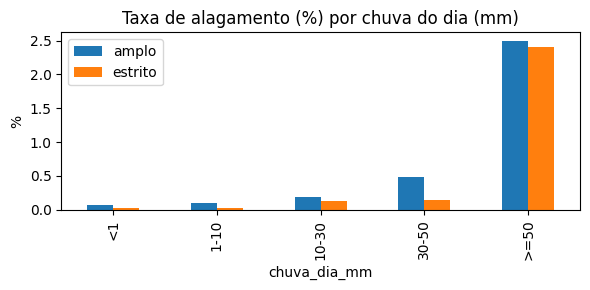

In [15]:
base_chuva = df[df["chuva_dia_mm"].notna()].copy()
faixas = pd.cut(base_chuva["chuva_dia_mm"], [-0.01, 1, 10, 30, 50, 1000], labels=["<1", "1-10", "10-30", "30-50", ">=50"])
tab = base_chuva.groupby(faixas).agg(linhas=("alagou", "size"), amplo=("alagou", "mean"), estrito=("alagou_estrito", "mean"))
tab[["amplo", "estrito"]] = (100 * tab[["amplo", "estrito"]]).round(3)
display(tab.rename(columns={"amplo": "% amplo", "estrito": "% estrito"}))
tab[["amplo", "estrito"]].plot(kind="bar", figsize=(6, 3), title="Taxa de alagamento (%) por chuva do dia (mm)")
plt.ylabel("%"); plt.tight_layout(); plt.show()

## 3. Preparação das variáveis

**O que entra e o que sai** (decisões importantes para evitar resultados enganosos):
- **Saem (vazamento do alvo):** `n_registros_alag` e `n_registros_alag_estrito` — contam os registros do *próprio dia* do alvo; usar isso seria "colar" a resposta.
- **Saem (identificadores / controle):** `bairro`, `regional`, `data`, `ano`, `horas_validas_dia`, `n_pontos_grade`, `local_casado`, e `lat_centro`/`lon_centro` (identificam o bairro e levariam o modelo a decorar lugares).
- **Linhas:** só dias com `chuva_dia_mm` medida (a estação falhou em ~3,5% dos dias; sem chuva não há o que prever nesses dias).
- **Cenário B** remove também `chuva_dia_mm`, `chuva_max_1h_mm` e as duas variáveis de maré *na hora do pico de chuva* (dependem de saber a chuva do dia).
- O histórico (`n_alag_*_365d`, `dias_desde_*`) já foi calculado **apenas com dias anteriores** — não vaza o futuro.

In [16]:
base = df[df["chuva_dia_mm"].notna()].reset_index(drop=True)

EXCLUIR = ["bairro", "regional", "data", "ano", "alagou", "alagou_estrito", "n_registros_alag", "n_registros_alag_estrito",
           "horas_validas_dia", "n_pontos_grade", "lat_centro", "lon_centro", "local_casado"]
FEATURES_A = [c for c in base.columns if c not in EXCLUIR]
DEPENDEM_CHUVA_DO_DIA = ["chuva_dia_mm", "chuva_max_1h_mm", "mare_na_hora_pico_chuva_m", "mare_subindo_na_hora_pico"]
FEATURES_B = [c for c in FEATURES_A if c not in DEPENDEM_CHUVA_DO_DIA]

assert not any(c.startswith("n_registros") for c in FEATURES_A), "vazamento do alvo!"
print("linhas:", len(base), "| features A:", len(FEATURES_A), "| features B:", len(FEATURES_B))
print(FEATURES_A)

linhas: 219882 | features A: 33 | features B: 29
['chuva_dia_mm', 'chuva_max_1h_mm', 'chuva_d1_mm', 'chuva_ult3d_mm', 'chuva_ult7d_mm', 'chuva_ult15d_mm', 'chuva_ult30d_mm', 'n_alag_bairro_365d', 'dias_desde_ultimo_alag', 'n_bairros_alag_dia_anterior', 'mes', 'dia_do_ano_sin', 'dia_do_ano_cos', 'fase_lunar', 'sizigia', 'mare_max_dia_m', 'mare_min_dia_m', 'mare_amp_dia_m', 'mare_na_hora_pico_chuva_m', 'mare_subindo_na_hora_pico', 'n_alag_estrito_bairro_365d', 'dias_desde_ultimo_alag_estrito', 'area_km2', 'alt_media_m', 'alt_mediana_m', 'alt_min_m', 'alt_max_m', 'alt_desvio_m', 'alt_p10_m', 'pct_pontos_abaixo_5m', 'pct_area_faixa_marginal', 'dist_faixa_media_m', 'dist_faixa_min_m']


## 4. Modelos
Dois modelos, escolhidos por serem adequados a dados tabulares pequenos e desbalanceados:

- **Regressão logística (referência interpretável).** Precisa de dados sem vazios e em escala parecida, então aplicamos: log nas chuvas e nos "dias desde" (distribuições muito assimétricas), um indicador "nunca houve evento" onde faltava, imputação pela mediana (calculada só no treino) e padronização. `class_weight="balanced"` compensa o desbalanceamento.
- **Gradient boosting (`HistGradientBoostingClassifier`).** Aceita vazios nativamente e capta interações (ex.: chuva forte *e* bairro com faixa marginal). Usamos árvores rasas, folhas grandes e regularização, porque há poucos positivos e o risco principal é **decorar**. Pesamos os positivos pela *raiz* da razão de desbalanceamento (um peso integral, ~1.400×, tende a causar sobreajuste com tão poucos positivos).

E um **baseline** sem aprendizado: ordenar apenas pela chuva (cenário A) ou pela chuva acumulada dos 3 dias anteriores (cenário B). **Se um modelo não superar o baseline, ele não acrescenta nada.**

In [17]:
COLS_LOG = ["chuva_dia_mm", "chuva_max_1h_mm", "chuva_d1_mm", "chuva_ult3d_mm", "chuva_ult7d_mm", "chuva_ult15d_mm", "chuva_ult30d_mm"]
COLS_DIAS = ["dias_desde_ultimo_alag", "dias_desde_ultimo_alag_estrito"]

def preparar_logit(X):
    # transformacoes sem estado (nao dependem do treino, entao nao ha vazamento)
    X = X.copy()
    for c in COLS_DIAS:
        if c in X:
            X[c + "_nunca"] = X[c].isna().astype(int)
            X[c] = np.log1p(X[c].fillna(3650))                  # nunca houve evento -> 10 anos
    for c in COLS_LOG:
        if c in X:
            X[c] = np.log1p(X[c].clip(lower=0))
    for c in ["mare_na_hora_pico_chuva_m", "mare_subindo_na_hora_pico"]:
        if c in X:
            X[c + "_sem_chuva"] = X[c].isna().astype(int)       # sem chuva no dia -> sem hora de pico
            X[c] = X[c].fillna(0)
    return X

class Logit:
    def fit(self, X, y):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               LogisticRegression(class_weight="balanced", C=0.1, max_iter=500))
        self.m.fit(X, y); return self
    def predict_proba1(self, X): return self.m.predict_proba(X)[:, 1]

class Boosting:
    def fit(self, X, y):
        pos = max(int(y.sum()), 1); peso_pos = np.sqrt((len(y) - pos) / pos)
        w = np.where(y == 1, peso_pos, 1.0)
        self.m = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200, min_samples_leaf=200,
                                                l2_regularization=1.0, early_stopping=False, random_state=SEED)
        self.m.fit(X, y, sample_weight=w); return self
    def predict_proba1(self, X): return self.m.predict_proba(X)[:, 1]

MODELOS = {"logistica": (Logit, preparar_logit), "boosting": (Boosting, lambda X: X)}

## 5. Avaliação: "deixa um ano de fora"
Para cada ano de 2014 a 2021: treina nos outros 7 e prevê o ano de fora. Juntamos as previsões de teste dos 8 anos (*out-of-fold*) e calculamos as métricas **uma vez** sobre todas elas.

**Métricas:**
- **PR-AUC (average precision):** qualidade do ranking quando o positivo é raro. O valor de um modelo aleatório é a própria taxa de positivos (~0,1%), então qualquer número bem acima disso é ganho real.
- **ROC-AUC:** complementar; costuma ser otimista com classes raras.
- **recall@top1% / @top5%:** se alertássemos apenas os 1% (ou 5%) de bairro-dias com maior risco, que fração dos alagamentos reais teríamos pegado? É a leitura mais próxima do uso operacional da Defesa Civil.

**Ressalva honesta:** "deixa um ano de fora" treina com anos *posteriores* ao ano testado. Como as variáveis não dependem do passado do próprio modelo, isso é aceitável aqui, mas na seção 8 fazemos também um teste estritamente cronológico.

In [18]:
def metricas(y, p):
    ordem = np.argsort(-p)
    out = {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p), "taxa base": y.mean()}
    for q in (0.01, 0.05):
        k = int(len(p) * q); out[f"recall@top{int(q*100)}%"] = y[ordem[:k]].sum() / y.sum()
    return out

def oof(base, features, alvo, nome_modelo):
    Modelo, prep = MODELOS[nome_modelo]
    X = prep(base[features]); y = base[alvo].values
    p = np.full(len(base), np.nan)
    for tr, te in LeaveOneGroupOut().split(X, y, groups=base["ano"]):
        m = Modelo().fit(X.iloc[tr], y[tr])
        p[te] = m.predict_proba1(X.iloc[te])
    return p

CENARIOS = {"A (chuva do dia conhecida)": FEATURES_A, "B (sem previsao de chuva)": FEATURES_B}
BASELINE_COL = {"A (chuva do dia conhecida)": "chuva_dia_mm", "B (sem previsao de chuva)": "chuva_ult3d_mm"}

resultados, previsoes = [], {}
for alvo in ["alagou_estrito", "alagou"]:
    y = base[alvo].values
    for cen, feats in CENARIOS.items():
        b = base[BASELINE_COL[cen]].fillna(0).values
        resultados.append({"alvo": alvo, "cenario": cen, "modelo": "baseline (so chuva)", **metricas(y, b)})
        for nm in MODELOS:
            p = oof(base, feats, alvo, nm)
            previsoes[(alvo, cen, nm)] = p
            resultados.append({"alvo": alvo, "cenario": cen, "modelo": nm, **metricas(y, p)})
            print("ok:", alvo, cen, nm)

tabela = pd.DataFrame(resultados).set_index(["alvo", "cenario", "modelo"]).round(4)
display(tabela)

ok: alagou_estrito A (chuva do dia conhecida) logistica
ok: alagou_estrito A (chuva do dia conhecida) boosting
ok: alagou_estrito B (sem previsao de chuva) logistica
ok: alagou_estrito B (sem previsao de chuva) boosting
ok: alagou A (chuva do dia conhecida) logistica
ok: alagou A (chuva do dia conhecida) boosting
ok: alagou B (sem previsao de chuva) logistica
ok: alagou B (sem previsao de chuva) boosting


PR-AUC  ROC-AUC  taxa base  recall@top1%  recall@top5%
alvo           cenario                    modelo                                                                     
alagou_estrito A (chuva do dia conhecida) baseline (so chuva)  0.0210   0.8376     0.0007        0.4259        0.5123
                                          logistica            0.0294   0.9048     0.0007        0.3457        0.5864
                                          boosting             0.0294   0.8728     0.0007        0.3457        0.5494
               B (sem previsao de chuva)  baseline (so chuva)  0.0047   0.7805     0.0007        0.1420        0.3333
                                          logistica            0.0166   0.8584     0.0007        0.2222        0.4877
                                          boosting             0.0051   0.7947     0.0007        0.1111        0.3333
alagou         A (chuva do dia conhecida) baseline (so chuva)  0.0142   0.7224     0.0013        0.2405        0.3574
                                          logistica            0.0198   0.8625     0.0013        0.2234        0.4948
                                          boosting             0.0271   0.8186     0.0013        0.2509        0.4880
               B (sem previsao de chuva)  baseline (so chuva)  0.0044   0.6851     0.0013        0.0859        0.2131
                                          logistica            0.0146   0.8366     0.0013        0.1581        0.4055
                                          boosting             0.0088   0.7838     0.0013        0.1134        0.2887

### Como ler a tabela
- Compare cada modelo com o **baseline da mesma linha de alvo e cenário**. Ganho em PR-AUC e em recall@top1% sobre o baseline é o que justifica usar Machine Learning.
- O cenário **A** deve ser melhor que o **B**: a diferença mede o quanto o projeto depende de uma boa **previsão de chuva** (que ainda precisa ser conseguida).
- Resultados do rótulo **amplo** e do **estrito** não são diretamente comparáveis em PR-AUC (taxas-base diferentes); compare o *ganho sobre o baseline* de cada um.

## 6. Resultado por ano
O desempenho pode variar muito entre anos, principalmente porque o número de positivos muda (ex.: 2018 tem 1 positivo estrito). **Anos com menos de 5 positivos não são confiáveis** e aparecem marcados.

In [19]:
alvo, cen, nm = "alagou_estrito", "A (chuva do dia conhecida)", "boosting"
p = previsoes[(alvo, cen, nm)]
linhas = []
for ano, g in base.groupby("ano"):
    y = g[alvo].values
    if y.sum() == 0: continue
    pa = p[g.index]
    linhas.append({"ano": ano, "positivos": int(y.sum()), "PR-AUC": average_precision_score(y, pa),
                   "recall@top1%": y[np.argsort(-pa)[:int(len(pa) * 0.01)]].sum() / y.sum(),
                   "confiavel": "sim" if y.sum() >= 5 else "NAO (poucos positivos)"})
display(pd.DataFrame(linhas).round(3).set_index("ano"))

,positivos,PR-AUC,recall@top1%,confiavel
ano,,,,
2014,64,0.069,0.344,sim
2015,34,0.021,0.029,sim
2016,30,0.106,0.633,sim
2017,9,0.170,0.444,sim
2018,1,0.000,0.000,NAO (poucos positivos)
2019,17,0.050,0.412,sim
2020,5,0.006,0.200,sim
2021,2,0.012,0.500,NAO (poucos positivos)


## 7. Quais variáveis importam? (importância por permutação)
Responde uma pergunta em aberto no documento do grupo: *"quais variáveis terão maior influência na previsão"*.

**Como funciona:** em cada ano de teste, embaralhamos uma variável por vez e medimos quanto a PR-AUC **cai**. Se cair muito, o modelo dependia dela. Fazemos a média entre os anos com pelo menos 5 positivos.

**Cuidado:** variáveis correlacionadas (as várias janelas de chuva; as várias medidas de altitude) dividem a importância entre si, então nenhuma parece decisiva sozinha.

,queda media da PR-AUC
chuva_dia_mm,0.0617
dist_faixa_min_m,0.0197
dias_desde_ultimo_alag_estrito,0.0099
alt_p10_m,0.0082
alt_media_m,0.0050
fase_lunar,0.0046
chuva_ult15d_mm,0.0036
n_alag_estrito_bairro_365d,0.0035
sizigia,0.0025
pct_pontos_abaixo_5m,0.0024


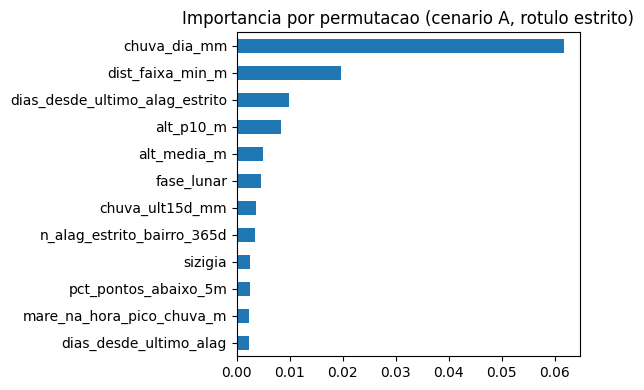

In [20]:
def importancia(base, features, alvo, repeticoes=3):
    X = base[features]; y = base[alvo].values
    queda = {f: [] for f in features}
    for tr, te in LeaveOneGroupOut().split(X, y, groups=base["ano"]):
        if y[te].sum() < 5: continue
        m = Boosting().fit(X.iloc[tr], y[tr])
        Xt, yt = X.iloc[te].copy(), y[te]
        ap0 = average_precision_score(yt, m.predict_proba1(Xt))
        for f in features:
            ganhos = []
            for _ in range(repeticoes):
                orig = Xt[f].values.copy()
                Xt[f] = RNG.permutation(orig)
                ganhos.append(ap0 - average_precision_score(yt, m.predict_proba1(Xt)))
                Xt[f] = orig
            queda[f].append(np.mean(ganhos))
    return pd.Series({f: np.mean(v) for f, v in queda.items()}).sort_values(ascending=False)

imp = importancia(base, FEATURES_A, "alagou_estrito")
display(imp.head(15).round(4).to_frame("queda media da PR-AUC"))
imp.head(12).iloc[::-1].plot(kind="barh", figsize=(6, 4), title="Importancia por permutacao (cenario A, rotulo estrito)")
plt.tight_layout(); plt.show()

## 8. Teste estritamente cronológico
Treina em **2014–2017** e testa em **2018–2021** (o futuro em relação ao treino). É o teste mais honesto sobre o uso real, mas tem **poucos positivos no teste**, então o resultado é só um sinal de coerência, não uma medida precisa.

In [21]:
alvo = "alagou_estrito"
tr = (base["ano"] <= 2017).values; te = ~tr
for nm in MODELOS:
    Modelo, prep = MODELOS[nm]
    X = prep(base[FEATURES_A]); y = base[alvo].values
    m = Modelo().fit(X[tr], y[tr]); p = m.predict_proba1(X[te])
    print(nm, {k: round(v, 4) for k, v in metricas(y[te], p).items()}, "| positivos no teste:", int(y[te].sum()))
b = base.loc[te, "chuva_dia_mm"].values
print("baseline", {k: round(v, 4) for k, v in metricas(base.loc[te, alvo].values, b).items()})

logistica {'PR-AUC': np.float64(0.0073), 'ROC-AUC': np.float64(0.8418), 'taxa base': np.float64(0.0002), 'recall@top1%': np.float64(0.12), 'recall@top5%': np.float64(0.24)} | positivos no teste: 25
boosting {'PR-AUC': np.float64(0.0213), 'ROC-AUC': np.float64(0.8347), 'taxa base': np.float64(0.0002), 'recall@top1%': np.float64(0.36), 'recall@top5%': np.float64(0.48)} | positivos no teste: 25
baseline {'PR-AUC': np.float64(0.007), 'ROC-AUC': np.float64(0.8938), 'taxa base': np.float64(0.0002), 'recall@top1%': np.float64(0.28), 'recall@top5%': np.float64(0.4)}


## 9. Níveis de risco (backlog 05)
O backlog pede transformar a probabilidade em **níveis compreensíveis**. Como a probabilidade bruta é sempre minúscula (eventos raros), usamos cortes por **posição no ranking**, calibrados nas previsões de teste:

| Nível | Critério (fatia das maiores pontuações) |
|---|---|
| 3 – muito alto | top 0,5% |
| 2 – alto | 0,5% a 2% |
| 1 – moderado | 2% a 7% |
| 0 – baixo | restante |

A tabela mostra, para cada nível, a taxa real de alagamento e a parcela dos eventos capturada. **Os cortes são uma proposta** — o grupo e a Defesa Civil devem decidir o equilíbrio entre alarme falso e omissão (a persona Camila pede exatamente isso). Quando houver previsão de chuva real, os cortes precisam ser recalibrados.

,linhas,eventos,taxa_%,% dos eventos
nivel,,,,
3,1100,43,3.91,26.5
2,3298,24,0.73,14.8
1,10994,28,0.25,17.3
0,204490,67,0.03,41.4


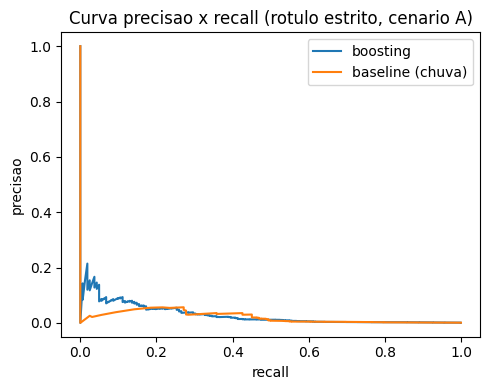

In [22]:
alvo, cen, nm = "alagou_estrito", "A (chuva do dia conhecida)", "boosting"
p = previsoes[(alvo, cen, nm)]; y = base[alvo].values
cortes = np.quantile(p, [0.93, 0.98, 0.995])
nivel = np.digitize(p, cortes)
niveis = pd.DataFrame({"nivel": nivel, "alagou": y}).groupby("nivel").agg(linhas=("alagou", "size"), eventos=("alagou", "sum"))
niveis["taxa_%"] = (100 * niveis["eventos"] / niveis["linhas"]).round(2)
niveis["% dos eventos"] = (100 * niveis["eventos"] / niveis["eventos"].sum()).round(1)
display(niveis.sort_index(ascending=False))

prec, rec, _ = precision_recall_curve(y, p)
b = base["chuva_dia_mm"].fillna(0).values
prec_b, rec_b, _ = precision_recall_curve(y, b)
plt.figure(figsize=(5, 4)); plt.plot(rec, prec, label="boosting"); plt.plot(rec_b, prec_b, label="baseline (chuva)")
plt.xlabel("recall"); plt.ylabel("precisao"); plt.title("Curva precisao x recall (rotulo estrito, cenario A)")
plt.legend(); plt.tight_layout(); plt.show()

# Parte 2 — Experimentos adicionais

A Parte 1 mostrou que o ML tem sinal, mas **não superou com folga** uma regra simples de chuva, e deixou quatro dúvidas. Cada experimento abaixo responde a uma delas.

| Experimento | Dúvida que responde |
|---|---|
| 1. Remover variáveis de "data" | `fase_lunar` e `sizigia` apareceram mais importantes que a chuva dos 15 dias anteriores, o que é implausível. Elas (e `dia_do_ano_*`) quase identificam um dia específico; como os eventos se concentram em poucos dias de tempestade, o modelo pode estar **decorando datas**. Se for isso, tirá-las não piora (e pode melhorar o cenário B) |
| 2. Baseline mais justo | O baseline da Parte 1 só olha a chuva e ignora *onde*. Um critério ingênuo "chuva × propensão histórica do bairro" é a referência correta para saber se o ML acrescenta algo |
| 3. Só dias de chuva forte | Em dia de chuva forte a chuva é igual para os 78 bairros, e a pergunta passa a ser **qual bairro alaga**. É onde o ML deveria agregar |
| 4. Intervalos de confiança | Com 162 eventos, não dá para saber se uma diferença de 13 eventos é real. Reamostramos **dias inteiros** (os eventos se agrupam por tempestade) |

**Pré-requisito:** execute a Parte 1 antes (estas células reutilizam `base`, `oof`, `metricas`, `previsoes` e `tabela`). Tempo estimado: 10 a 15 minutos, a maior parte no experimento 4.

## Experimento 1 — Sem variáveis de "impressão digital de data"
Removemos `fase_lunar`, `sizigia`, `dia_do_ano_sin` e `dia_do_ano_cos`. Mantemos `mes` (só 12 valores, não identifica um dia) e as variáveis de maré (calculadas a partir da data, mas que carregam a informação física da maré).

**Como ler:** compare as linhas "A2/B2" com as "A/B" da Parte 1.
- Se **A2 ≈ A** e **B2 ≥ B** (principalmente o boosting), a hipótese de decorar datas se sustenta: essas variáveis não ajudavam e atrapalhavam.
- Se A2/B2 forem **piores**, as variáveis carregavam sinal real (ex.: a sazonalidade da estação chuvosa) e a hipótese cai.

In [23]:
FEATURES_FP = ["fase_lunar", "sizigia", "dia_do_ano_sin", "dia_do_ano_cos"]
FEATURES_A2 = [c for c in FEATURES_A if c not in FEATURES_FP]
FEATURES_B2 = [c for c in FEATURES_B if c not in FEATURES_FP]
CENARIOS2 = {"A2 (sem datas)": FEATURES_A2, "B2 (sem datas)": FEATURES_B2}

y = base["alagou_estrito"].values
res2, prev2 = [], {}
for cen, feats in CENARIOS2.items():
    for nm in MODELOS:
        p = oof(base, feats, "alagou_estrito", nm)
        prev2[(cen, nm)] = p
        res2.append({"cenario": cen, "modelo": nm, **metricas(y, p)})
        print("ok:", cen, nm)

antes = tabela.loc["alagou_estrito"].reset_index()
comparacao = pd.concat([antes, pd.DataFrame(res2)], ignore_index=True)
display(comparacao.set_index(["cenario", "modelo"]).round(4))

ok: A2 (sem datas) logistica
ok: A2 (sem datas) boosting
ok: B2 (sem datas) logistica
ok: B2 (sem datas) boosting


PR-AUC  ROC-AUC  taxa base  recall@top1%  recall@top5%
cenario                    modelo                                                                     
A (chuva do dia conhecida) baseline (so chuva)  0.0210   0.8376     0.0007        0.4259        0.5123
                           logistica            0.0294   0.9048     0.0007        0.3457        0.5864
                           boosting             0.0294   0.8728     0.0007        0.3457        0.5494
B (sem previsao de chuva)  baseline (so chuva)  0.0047   0.7805     0.0007        0.1420        0.3333
                           logistica            0.0166   0.8584     0.0007        0.2222        0.4877
                           boosting             0.0051   0.7947     0.0007        0.1111        0.3333
A2 (sem datas)             logistica            0.0337   0.8997     0.0007        0.3704        0.6296
                           boosting             0.0412   0.8741     0.0007        0.3519        0.5617
B2 (sem datas)             logistica            0.0189   0.8657     0.0007        0.2531        0.5123
                           boosting             0.0070   0.8128     0.0007        0.1420        0.3519

## Experimento 2 — Baseline mais justo: chuva × propensão do bairro
Dois critérios **sem aprendizado de máquina**, calculados usando só os anos de treino de cada rodada (como o modelo):
- **só bairro:** ordena pelos bairros que mais tiveram alagamento no passado, ignorando a chuva;
- **chuva × bairro:** `taxa de alagamento da faixa de chuva` × `propensão relativa do bairro` (eventos do bairro suavizados, relativos à média dos bairros).

Se o modelo de ML não bate o "chuva × bairro", ele está apenas redescobrindo duas tabelas simples.

In [24]:
FAIXAS = [-0.01, 1, 10, 30, 50, 1000]

def baselines_bairro(base, alvo):
    faixa = pd.cut(base["chuva_dia_mm"], FAIXAS, labels=False)
    y = base[alvo].values
    p_chuva_bairro = np.zeros(len(base)); p_so_bairro = np.zeros(len(base))
    for tr, te in LeaveOneGroupOut().split(base, y, groups=base["ano"]):
        taxa_faixa = pd.Series(y[tr]).groupby(faixa.iloc[tr].values).mean()
        ev_b = pd.Series(y[tr]).groupby(base["bairro"].iloc[tr].values).sum()
        prop = (ev_b + 1) / (ev_b.mean() + 1)                 # propensao relativa, suavizada
        f_te = faixa.iloc[te].map(taxa_faixa).fillna(0).values
        b_te = base["bairro"].iloc[te].map(prop).fillna(1.0).values
        p_chuva_bairro[te] = f_te * b_te
        p_so_bairro[te] = b_te
    return p_chuva_bairro, p_so_bairro

def desempata(s, escala):
    # ruido minusculo so para quebrar empates de forma aleatoria (sem favorecer a ordem das linhas)
    return s + RNG.random(len(s)) * escala

p_cb, p_sb = baselines_bairro(base, "alagou_estrito")
SC = {
    "baseline: so chuva": desempata(base["chuva_dia_mm"].values, 1e-6),
    "baseline: so bairro (historico)": desempata(p_sb, 1e-9),
    "baseline: chuva x bairro": desempata(p_cb, 1e-12),
    "logistica A": previsoes[("alagou_estrito", "A (chuva do dia conhecida)", "logistica")],
    "boosting A": previsoes[("alagou_estrito", "A (chuva do dia conhecida)", "boosting")],
    "logistica A2 (sem datas)": prev2[("A2 (sem datas)", "logistica")],
    "boosting A2 (sem datas)": prev2[("A2 (sem datas)", "boosting")],
}
tab2 = pd.DataFrame({nome: metricas(y, s) for nome, s in SC.items()}).T
display(tab2.round(4))

,PR-AUC,ROC-AUC,taxa base,recall@top1%,recall@top5%
baseline: so chuva,0.0204,0.8400,0.0007,0.4259,0.5123
baseline: so bairro (historico),0.0031,0.7990,0.0007,0.0556,0.2901
baseline: chuva x bairro,0.0440,0.8410,0.0007,0.4383,0.5926
logistica A,0.0294,0.9048,0.0007,0.3457,0.5864
boosting A,0.0294,0.8728,0.0007,0.3457,0.5494
logistica A2 (sem datas),0.0337,0.8997,0.0007,0.3704,0.6296
boosting A2 (sem datas),0.0412,0.8741,0.0007,0.3519,0.5617


## Experimento 3 — Só dias de chuva forte (≥ 30 mm)
Aqui a chuva é a mesma para todos os bairros do dia, então o baseline "só chuva" **não consegue distinguir bairros** (ele só ordena os dias). A pergunta é: entre os bairros de um dia chuvoso, o modelo sabe apontar **qual alaga**? Esse é o ganho que o ML deveria trazer.

A taxa base nesse subconjunto é bem maior (cerca de 1%), então as métricas não são comparáveis às da Parte 1; compare os modelos entre si. Usamos recall nos top 5%, 10% e 20% porque o subconjunto é pequeno (~7,6 mil linhas).

In [25]:
forte = (base["chuva_dia_mm"] >= 30).values
yf = y[forte]
print(f"dias de chuva forte: {forte.sum()} linhas | positivos: {int(yf.sum())} | taxa base: {yf.mean():.4f}")

def metricas_sub(yy, p, qs=(0.05, 0.10, 0.20)):
    ordem = np.argsort(-p)
    out = {"PR-AUC": average_precision_score(yy, p), "ROC-AUC": roc_auc_score(yy, p)}
    for q in qs:
        k = int(len(p) * q); out[f"recall@top{int(q*100)}%"] = yy[ordem[:k]].sum() / yy.sum()
    return out

tab3 = pd.DataFrame({nome: metricas_sub(yf, s[forte]) for nome, s in SC.items()}).T
display(tab3.round(4))

dias de chuva forte: 7644 linhas | positivos: 80 | taxa base: 0.0105


,PR-AUC,ROC-AUC,recall@top5%,recall@top10%,recall@top20%
baseline: so chuva,0.0380,0.8318,0.1875,0.5500,0.5750
baseline: so bairro (historico),0.0596,0.8397,0.3500,0.5375,0.6750
baseline: chuva x bairro,0.0836,0.8864,0.4375,0.5875,0.8750
logistica A,0.0882,0.7863,0.3625,0.4750,0.5750
boosting A,0.0560,0.7942,0.3000,0.4750,0.6000
logistica A2 (sem datas),0.1178,0.8235,0.4125,0.5625,0.6625
boosting A2 (sem datas),0.0762,0.8065,0.3750,0.4625,0.6375


## Experimento 4 — Intervalos de confiança (reamostragem de dias)
Reamostramos **dias inteiros** com reposição (todos os bairros do dia juntos), porque os eventos se agrupam por tempestade e as linhas de um mesmo dia não são independentes. Repetimos 200 vezes e calculamos:
- o intervalo de 95% de cada métrica;
- a **diferença pareada** de cada modelo contra os baselines (mesmas amostras) e a fração de reamostras em que o modelo ganha.

**Regra de leitura:** se o intervalo da diferença **inclui zero** (ou a fração de ganho fica entre ~5% e ~95%), trate como **empate**. Só vale afirmar "o modelo supera o baseline" se o intervalo ficar acima de zero.

In [26]:
def bootstrap_dias(base, y, scores, B=200, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_por_dia = base.groupby("data").indices                 # data -> posicoes das linhas do dia
    dias = list(idx_por_dia.keys())
    nomes = list(scores)
    ap = {n: [] for n in nomes}; rc = {n: [] for n in nomes}
    for _ in range(B):
        sel = rng.integers(0, len(dias), len(dias))
        idx = np.concatenate([idx_por_dia[dias[i]] for i in sel])
        yy = y[idx]
        if yy.sum() == 0:
            continue
        k = int(len(idx) * 0.05)
        for n in nomes:
            s = scores[n][idx]
            ap[n].append(average_precision_score(yy, s))
            rc[n].append(yy[np.argsort(-s)[:k]].sum() / yy.sum())
    return {n: np.array(v) for n, v in ap.items()}, {n: np.array(v) for n, v in rc.items()}

ap_b, rc_b = bootstrap_dias(base, y, SC)

def resumo(d):
    return pd.DataFrame({n: {"media": v.mean(), "IC95 inf": np.percentile(v, 2.5), "IC95 sup": np.percentile(v, 97.5)}
                         for n, v in d.items()}).T
print("PR-AUC"); display(resumo(ap_b).round(4))
print("recall@top5%"); display(resumo(rc_b).round(3))

def diferencas(d, base_nome, modelos):
    linhas = {}
    for m in modelos:
        dif = d[m] - d[base_nome]
        linhas[m] = {"dif media": dif.mean(), "IC95 inf": np.percentile(dif, 2.5),
                     "IC95 sup": np.percentile(dif, 97.5), "% reamostras em que ganha": 100 * (dif > 0).mean()}
    return pd.DataFrame(linhas).T

modelos_ml = ["logistica A", "boosting A", "logistica A2 (sem datas)", "boosting A2 (sem datas)"]
for ref in ["baseline: so chuva", "baseline: chuva x bairro"]:
    print(f"\nPR-AUC: modelo MENOS {ref}"); display(diferencas(ap_b, ref, modelos_ml).round(4))
    print(f"recall@top5%: modelo MENOS {ref}"); display(diferencas(rc_b, ref, modelos_ml).round(3))

PR-AUC


,media,IC95 inf,IC95 sup
baseline: so chuva,0.0233,0.0112,0.0412
baseline: so bairro (historico),0.0032,0.0019,0.0045
baseline: chuva x bairro,0.0480,0.0182,0.0877
logistica A,0.0338,0.0149,0.0757
boosting A,0.0329,0.0119,0.0648
logistica A2 (sem datas),0.0383,0.0176,0.0734
boosting A2 (sem datas),0.0455,0.0168,0.0888


recall@top5%


,media,IC95 inf,IC95 sup
baseline: so chuva,0.514,0.369,0.653
baseline: so bairro (historico),0.291,0.242,0.354
baseline: chuva x bairro,0.590,0.464,0.697
logistica A,0.583,0.491,0.665
boosting A,0.544,0.411,0.654
logistica A2 (sem datas),0.630,0.539,0.709
boosting A2 (sem datas),0.553,0.429,0.650



PR-AUC: modelo MENOS baseline: so chuva


,dif media,IC95 inf,IC95 sup,% reamostras em que ganha
logistica A,0.0105,-0.0129,0.0532,77.5
boosting A,0.0096,-0.0116,0.0391,81.5
logistica A2 (sem datas),0.0150,-0.0096,0.0566,87.0
boosting A2 (sem datas),0.0222,-0.0021,0.0544,96.5


... (2 outputs left out)


PR-AUC: modelo MENOS baseline: chuva x bairro


,dif media,IC95 inf,IC95 sup,% reamostras em que ganha
logistica A,-0.0142,-0.0486,0.0275,18.0
boosting A,-0.0151,-0.0443,0.0110,13.0
logistica A2 (sem datas),-0.0097,-0.0414,0.0308,28.5
boosting A2 (sem datas),-0.0025,-0.0299,0.0256,44.5


recall@top5%: modelo MENOS baseline: chuva x bairro


,dif media,IC95 inf,IC95 sup,% reamostras em que ganha
logistica A,-0.007,-0.095,0.098,39.5
boosting A,-0.046,-0.179,0.076,20.0
logistica A2 (sem datas),0.040,-0.048,0.148,75.5
boosting A2 (sem datas),-0.037,-0.166,0.075,24.0


## Como concluir a Parte 2
Preencha com base nas tabelas acima:

1. **Datas (exp. 1):** tirar `fase_lunar`/`sizigia`/`dia_do_ano_*` piorou, manteve ou melhorou? O boosting do cenário B se recuperou?
2. **Baseline justo (exp. 2):** o ML supera "chuva × bairro"? Em quanto? Se não supera, o ganho da Parte 1 vinha de saber *onde* já alagou, algo que uma tabela simples também sabe.
3. **Onde alaga (exp. 3):** em dias de chuva forte, o ML separa bem os bairros que alagam? Compare com "só bairro (histórico)".
4. **Incerteza (exp. 4):** os intervalos das diferenças incluem zero? Se sim, a conclusão correta é **empate estatístico**.

**Próximo passo fora do notebook (a lacuna de dados):** a chuva é igual para todos os bairros porque há uma só estação. Para o modelo distinguir bairros por *onde choveu*, é preciso incluir mais estações (APAC e CEMADEN). É o que mais deve aumentar o desempenho — nenhum ajuste de modelo substitui isso.

## 10. Limitações (leia antes de apresentar os números)
- **O rótulo é um registro administrativo**, não alagamento medido. O modelo pode aprender *onde a Defesa Civil atua*, e não só *onde alaga*. Em 43 dos 291 positivos amplos com chuva medida, a estação registrou 0 mm.
- **Uma só estação de chuva (INMET A301)** para a cidade inteira: todos os bairros recebem a mesma chuva no mesmo dia. O modelo só diferencia bairros pelas características estáticas e pelo histórico.
- **Chuva do dia é observada, não prevista.** O cenário A é um teto; o B é mais realista até existir previsão de chuva.
- **Maré é astronômica** (sem maré meteorológica) e não mostrou efeito claro na análise exploratória.
- **Altitude média do bairro é um mau indicador** (mostrou sinal invertido). O ideal é a altitude relativa à drenagem (HAND), ainda não calculada.
- **Dados só até 2021.** Faltam chuva de 2022+ (APAC/CEMADEN) para validar em dados recentes.
- **Poucos positivos** (162 estritos): as métricas têm incerteza grande; trate diferenças pequenas entre modelos como empate.

## 11. Conclusões do grupo (preencher)
- O modelo supera o baseline? Em quanto (PR-AUC e recall@top1%)?
- Qual a diferença entre os cenários A e B e o que isso implica para o projeto?
- Quais variáveis mais importam?
- Quais níveis de risco o grupo adotará?
- Próximos passos (dados de 2022+, HAND, previsão de chuva, validação com o sensor ESP32):